# Lab 2 — Clean, impute, visualise: `clients_raw.csv` — **TEACHER SOLUTION**
**Data Analysis — Master AI / Master RSD** · Chapter 2: Data exploration and preparation

*Clean, impute, visualise: the full cycle on a concrete case.*

**Lab objectives**
1. **Clean** a raw dataset: detect and fix duplicates, inconsistencies and format problems → *reliable data ready for analysis*.
2. **Handle missing values**: apply several imputation methods and compare their impact → *choose the most suitable method*.
3. **Visualise** the data with Matplotlib and Seaborn → *understand and communicate*.
4. **Document every decision** (choices, justifications, results) in this notebook → *traceability and reproducibility*.

| Duration | Organisation | Data | Deliverable |
|---|---|---|---|
| 2 sessions of 2 h (4 h total) | Pairs · Jupyter notebook | `clients_raw.csv` (fictional, provided) | Completed notebook + conclusions |

**Prerequisites:** exploration from chapter 1 (Lab 1) and the methods of sections 4 to 7 of chapter 2.

⭐ **Continuity:** this lab follows Lab 1 — same dataset (`clients.csv`), in a "raw" version with injected defects.

⚠️ **Order of operations (must be respected)**: ① Deduplicate → ② Harmonise → ③ Type → ④ Validate ranges. This order avoids introducing errors in the following steps.

**How to use**: complete the cells marked `# TODO`, then run the **✅ Self-check** cell that follows. Answer the questions in the **✍️** cells.

## Part 0 — Generating the dataset (teacher)
`clients_raw.csv` is built from Lab 1's `clients.csv` (1,000 clients, 37 NaN in income, 1 outlier income of 999,999), with columns translated to English.
Injected defects, with a fixed seed:
- **12 invalid ages**: 4 unreadable texts (`"thirty"`, `"?"`, `"45 yrs"`, `"unknown"`) and 8 out-of-range values (150, −3, 999…);
- **60 lowercase segments** (`a`, `b`) → inconsistent categories;
- **12 exact duplicates**, then rows are shuffled.

Expected result after cleaning: **(988, 8)**, as on the slide.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(2027)              # fixed seed -> identical file on every run
base = pd.read_csv("../clients.csv", sep=";").rename(columns={
    "revenu": "income", "nb_enfants": "n_children", "anciennete": "tenure", "nb_achats": "n_purchases"})
base["email"] = base["email"].str.replace("exemple", "example")
raw = base.astype({"age": "object", "income": "Int64"})

# 1. 12 invalid ages (on rows whose income is known and plausible)
ok = raw.index[raw["income"].notna() & (raw["income"] < 200000)]
idx_age = rng.choice(ok, size=12, replace=False)
raw.loc[idx_age, "age"] = ["thirty", "?", "45 yrs", "unknown", 150, -3, 999, 135, 200, -1, 121, 180]

# 2. Inconsistent categories: 60 A/B segments written in lowercase
ab = raw.index[raw["segment"].isin(["A", "B"])]
idx_seg = rng.choice(ab, size=60, replace=False)
raw.loc[idx_seg, "segment"] = raw.loc[idx_seg, "segment"].str.lower()

# 3. 12 exact duplicates, then shuffle the rows
duplicates = raw.loc[rng.choice(raw.index, size=12, replace=False)]
raw = pd.concat([raw, duplicates]).sample(frac=1, random_state=2027).reset_index(drop=True)

raw.to_csv("../TP2/EN/clients_raw.csv", sep=";", index=False, encoding="utf-8")
print("clients_raw.csv written:", raw.shape)

clients_raw.csv written: (1012, 8)


---
## Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer, KNNImputer

sns.set_theme(style="whitegrid")   # tip: more readable plots
pd.set_option("display.max_columns", 20)

---
## Step 1 — Cleaning with Pandas: duplicates and inconsistencies
*A complete, commented script — to reproduce cell by cell.*

**Good practice:** check `shape` before/after each step — the notebook should **tell the story** of the cleaning.

### 1.0 Load the raw file
The separator is `;` (as in Lab 1).

In [3]:
df = pd.read_csv("../TP2/EN/clients_raw.csv", sep=";")

print(df.shape)
df.head()

(1012, 8)


,id,age,income,n_children,tenure,n_purchases,email,segment
0,871,60,NaN,1,0,0,client0871@example.dz,C
1,587,51,38100.0,2,16,9,client0587@example.dz,A
2,550,33,45700.0,0,17,15,client0550@example.dz,A
3,950,34,74100.0,1,11,12,client0950@example.dz,A
4,906,61,78100.0,1,3,5,client0906@example.dz,b


In [4]:
df.dtypes   # look at the type of the age column: why is it not numeric?

id               int64
age             object
income         float64
n_children       int64
tenure           int64
n_purchases      int64
email           object
segment         object
dtype: object

✅ **Self-check**

In [5]:
assert df.shape == (1012, 8), f"Expected (1012, 8), got {df.shape} -> check sep=';'"
print("✅ 1.0 correct")

✅ 1.0 correct


💡 *Point out*: `age` has type `object` although it is an age → **at least one value is not a number**. This is the signal we handle in 1.3.

### 1.1 Duplicates: count, then remove
Count the **exactly duplicated** rows with `duplicated()`, then remove them with `drop_duplicates(keep="first")`.

In [6]:
n_duplicates = df.duplicated().sum()
print("Duplicates found:", n_duplicates)

df = df.drop_duplicates(keep="first")
print(df.shape)

Duplicates found: 12
(1000, 8)


✅ **Self-check**

In [7]:
assert n_duplicates == 12, "12 duplicates expected"
assert df.shape == (1000, 8), "1000 rows expected after deduplication"
assert df["id"].is_unique, "every id must now be unique"
print("✅ 1.1 correct")

✅ 1.1 correct


💡 *Question to ask*: `keep="first"` or `keep="last"`? Here it makes no difference (**exact** duplicates). If the rows differed (an updated client record), you would keep the most recent one → `keep="last"` after sorting by date.

### 1.2 Harmonise categories
First display the counts of `segment`, then replace the inconsistent categories.

**Good practice:** `replace()` **before** any analysis of categories — otherwise "a" and "A" count as two segments.

In [8]:
df["segment"].value_counts()

segment
A    382
B    291
C    267
b     30
a     30
Name: count, dtype: int64

In [9]:
df["segment"] = df["segment"].replace({"a": "A", "b": "B"})

df["segment"].value_counts()

segment
A    412
B    321
C    267
Name: count, dtype: int64

✅ **Self-check**

In [10]:
assert set(df["segment"].unique()) == {"A", "B", "C"}, "only A, B, C should remain"
assert df["segment"].value_counts()["A"] == 412, "we get back Lab 1's 412 A clients"
print("✅ 1.2 correct")

✅ 1.2 correct


💡 *More robust version*: `df["segment"].str.strip().str.upper()` fixes **all** variants (spaces, lowercase) without listing them. The explicit `replace` has the advantage of **documenting** exactly what was fixed.

### 1.3 Types and value ranges
1. First look at which `age` values are **not numeric** (cell provided).
2. Convert `age` to numeric with `pd.to_numeric(..., errors="coerce")`: unreadable values become `NaN`.
3. Keep only **realistic** ages (between 0 and 120) with `between`.

**Good practice:** `errors="coerce"` turns unreadable values into `NaN` — handled in the next step.

In [11]:
age_num = pd.to_numeric(df["age"], errors="coerce")
print("Non-numeric values:", df.loc[age_num.isna(), "age"].tolist())
print("Out-of-range values:", df.loc[~age_num.between(0, 120) & age_num.notna(), "age"].tolist())

Non-numeric values: ['45 yrs', '?', 'thirty', 'unknown']
Out-of-range values: ['200', '150', '-3', '999', '121', '-1', '135', '180']


In [12]:
df["age"] = pd.to_numeric(df["age"], errors="coerce")
df = df[df["age"].between(0, 120)]   # realistic age (NaN are excluded too)

print(df.shape)

(988, 8)


✅ **Self-check**

In [13]:
assert df.shape == (988, 8), f"Expected (988, 8), got {df.shape}"
assert df["age"].dtype == "float64", "age must be numeric"
assert df["age"].between(18, 87).all(), "the remaining ages are those from Lab 1 (18 to 87)"
print("✅ 1.3 correct — Final result: (988, 8) ← 12 duplicates removed, age ranges validated")

✅ 1.3 correct — Final result: (988, 8) ← 12 duplicates removed, age ranges validated


**Expected answer:** `NaN.between(...)` is `False`, so the 4 unreadable ages are removed along with the 8 out-of-range ones. This is acceptable: 12 rows out of 1,000 (1.2%), and we cannot tell whether the rest of the record is reliable. If these errors were **numerous** or concentrated in one group (e.g. all clients of one branch), dropping them would bias the sample: we would rather set age to `NaN` and impute it in step 2.

### 1.4 Validate the income range
In Lab 1 we found a client at **999,999 DA**: it is a data-entry error code, not a real income.
Replace this value with `NaN` (it will be imputed in step 2).

In [14]:
print("Clients at 999,999:", (df["income"] == 999999).sum())

df.loc[df["income"] == 999999, "income"] = np.nan

print("Max income:", df["income"].max(), "| NaN:", df["income"].isna().sum())

Clients at 999,999: 1
Max income: 185000.0 | NaN: 38


✅ **Self-check**

In [15]:
assert df["income"].max() < 200000, "the 999999 code must be gone"
assert df["income"].isna().sum() == 38, "37 original NaN + 1 error code = 38"
assert df.shape == (988, 8), "do not drop the row: only the income is wrong"
print("✅ 1.4 correct")

✅ 1.4 correct


**Expected answer:** only the `income` cell is wrong; age, tenure, segment… are valid. Dropping the row would lose information. Setting it to `NaN` turns the problem into a **missing value**, which step 2 knows how to handle.

---
## Step 2 — Handling missing values: comparing three methods
*Same dataset, three imputation strategies, three results to discuss.*

1. **Deletion** — drop incomplete rows (`dropna`)
2. **Median** — impute with the median (robust to outliers)
3. **k-NN** — impute with the *k* nearest neighbours

### 2.0 Missing-value rate before treatment

In [16]:
rate = df.isnull().mean().round(3)
rate

id             0.000
age            0.000
income         0.038
n_children     0.000
tenure         0.000
n_purchases    0.000
email          0.000
segment        0.000
dtype: float64

✅ **Self-check**

In [17]:
assert rate["income"] == 0.038, "≈ 3.8% of incomes missing"
assert rate.drop("income").sum() == 0, "only income has missing values"
print("✅ 2.0 correct")

✅ 2.0 correct


### 2.1 Apply the three methods
scikit-learn imputers only work on **numeric** columns: we use `num_cols` (without `id`, which has no statistical meaning).

`fit_transform` returns a NumPy array: we put it back into a `DataFrame` with the **same columns and the same index** as `df`.

In [18]:
num_cols = ["age", "income", "n_children", "tenure", "n_purchases"]

# Method 1: deletion
df_del = df.dropna()

# Method 2: median (robust to outliers)
imp = SimpleImputer(strategy="median")
df_med = pd.DataFrame(imp.fit_transform(df[num_cols]), columns=num_cols, index=df.index)

# Method 3: k nearest neighbours
knn = KNNImputer(n_neighbors=5)
df_knn = pd.DataFrame(knn.fit_transform(df[num_cols]), columns=num_cols, index=df.index)

✅ **Self-check**

In [19]:
assert len(df_del) == 950, "988 - 38 incomplete rows = 950"
assert df_med.shape == df_knn.shape == (988, 5)
assert df_med.isna().sum().sum() == 0 and df_knn.isna().sum().sum() == 0
assert (df_med.loc[df["income"].isna(), "income"] == df["income"].median()).all(), "median = a single value"
print("✅ 2.1 correct")

✅ 2.1 correct


### 2.2 Compare the three strategies
Build a table giving, for each method: the number of **rows kept**, of **missing values** (income), the **mean income**, the income **standard deviation**, and the difference in mean income compared with the raw data (**Δ vs raw**).

In [20]:
methods = {"Raw (reference)": df, "Deletion": df_del, "Median": df_med, "k-NN (k=5)": df_knn}

comparison = pd.DataFrame({
    "rows":        {name: len(d) for name, d in methods.items()},
    "missing":     {name: d["income"].isna().sum() for name, d in methods.items()},
    "mean_income": {name: d["income"].mean() for name, d in methods.items()},
    "std_income":  {name: d["income"].std() for name, d in methods.items()},
}).round(0)
comparison["delta_vs_raw"] = comparison["mean_income"] - comparison.loc["Raw (reference)", "mean_income"]
comparison

,rows,missing,mean_income,std_income,delta_vs_raw
Raw (reference),988,38,44735.0,22937.0,0.0
Deletion,950,0,44735.0,22937.0,0.0
Median,988,0,44543.0,22512.0,-192.0
k-NN (k=5),988,0,44664.0,22580.0,-71.0


✅ **Self-check**

In [21]:
assert list(comparison["rows"]) == [988, 950, 988, 988]
assert list(comparison["missing"]) == [38, 0, 0, 0]
assert comparison.loc["Deletion", "delta_vs_raw"] == 0
assert comparison.loc["Median", "delta_vs_raw"] < comparison.loc["k-NN (k=5)", "delta_vs_raw"] < 0
assert comparison.loc["Median", "std_income"] < comparison.loc["k-NN (k=5)", "std_income"] < comparison.loc["Raw (reference)", "std_income"]
print("✅ 2.2 correct")

✅ 2.2 correct


### 2.3 Where do the imputed values land?
Provided cell: we overlay the distribution of **observed** incomes and the 38 values **imputed** by each method.

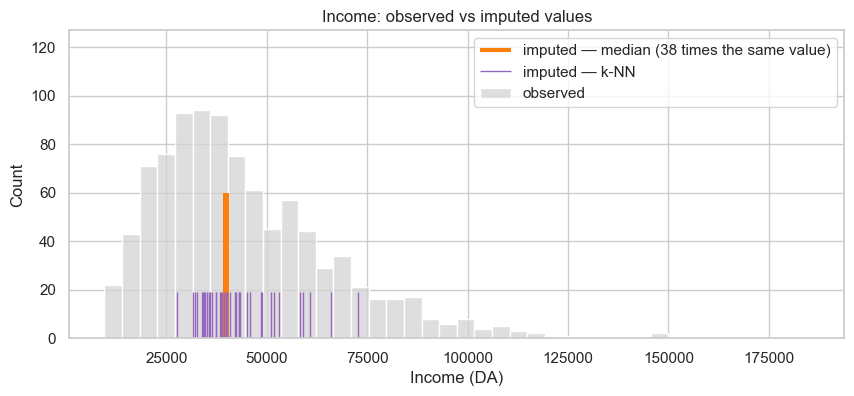

In [22]:
missing = df["income"].isna()

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(df["income"], bins=40, color="lightgray", label="observed", ax=ax)
ax.vlines(df_med.loc[missing, "income"], 0, 60, color="tab:orange", lw=3, label="imputed — median (38 times the same value)")
sns.rugplot(df_knn.loc[missing, "income"], color="tab:purple", height=0.15, lw=2, label="imputed — k-NN", ax=ax)
ax.set_title("Income: observed vs imputed values")
ax.set_xlabel("Income (DA)")
ax.legend()
plt.show()

**Expected answers**
1. `mean()` **already ignores NaN**: the "raw" mean is computed on the 950 known incomes, exactly as after `dropna()`. But deletion **throws away 38 whole clients** (valid age, tenure, segment…): information is lost, and the result is biased if NaN are not randomly spread (MAR / MNAR). Here the Lab 1 NaN were drawn at random (MCAR), which is why the mean does not move.
2. Income is **right-skewed**: median (≈ 39,750 DA) < mean (≈ 44,700 DA). Replacing 38 values with the median pulls the mean down. And 38 **identical** values create an artificial spike → the spread (standard deviation) is **underestimated**.
3. **k-NN**: it keeps all 988 rows, distorts the mean and standard deviation the least, and produces **varied** values that depend on the client's profile. The median remains a good, simple and robust default when the missing rate is low.

⚠️ The figures differ from the slide (illustrative data), but the **ranking** is the same: k-NN is closest to the reference, then the median.

### 2.4 Going further — really evaluating the imputation
Comparing means does not tell us whether the imputed values are **correct**. Classic method: **hide** values we know, impute them, then measure the error.

1. Hide 100 **known** incomes (random draw, seed 0).
2. Impute with the median, raw k-NN, and k-NN on **standardised** data (`StandardScaler`, section 6 of the course).
3. Compare the **mean absolute error** (MAE) between imputed and true values.

In [23]:
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(0)
hidden = rng.choice(df.index[df["income"].notna()], size=100, replace=False)
truth = df.loc[hidden, "income"]

test = df[num_cols].copy()
test.loc[hidden, "income"] = np.nan

def mae(filled):
    """Mean absolute error on the 100 hidden incomes."""
    return (filled.loc[hidden, "income"] - truth).abs().mean()

def to_df(array):
    return pd.DataFrame(array, columns=num_cols, index=test.index)

def knn_scaled(X):
    """Standardise -> k-NN -> back to the original scale."""
    sc = StandardScaler()
    filled = sc.inverse_transform(KNNImputer(n_neighbors=5).fit_transform(sc.fit_transform(X)))
    return pd.DataFrame(filled, columns=X.columns, index=X.index)

with_segment = pd.concat([test, pd.get_dummies(df["segment"], dtype=float)], axis=1)   # one-hot (section 7)

results = {
    "Median": mae(to_df(SimpleImputer(strategy="median").fit_transform(test))),
    "Raw k-NN": mae(to_df(KNNImputer(n_neighbors=5).fit_transform(test))),
    "Standardised k-NN": mae(knn_scaled(test)),
    "Standardised k-NN + segment": mae(knn_scaled(with_segment)),
    "Median per segment": mae(test.assign(income=test["income"].fillna(
        test.groupby(df["segment"])["income"].transform("median")))),
}
pd.Series(results, name="MAE (DA)").round(0)

Median                         19201.0
Raw k-NN                       18509.0
Standardised k-NN              18184.0
Standardised k-NN + segment    16227.0
Median per segment             15757.0
Name: MAE (DA), dtype: float64

**Expected answer** (MAE on 100 hidden incomes)

| Method | MAE ≈ |
|---|---|
| Global median | 19,200 DA |
| Raw k-NN | 18,500 DA |
| Standardised k-NN | 18,200 DA |
| Standardised k-NN + segment | 16,200 DA |
| Median per segment | 15,800 DA |

- k-NN does slightly better than the median: its neighbours are chosen using `n_purchases`, which is correlated with income (r ≈ 0.29).
- **Without standardisation**, the distance is dominated by the variables with the largest values (age, tenure), which have **no link** with income → poorly chosen neighbours. Standardising gives every variable the same weight (section 6).
- The clearest gain comes from the **segment**, strongly linked to income (A ≫ B > C). A simple **median per segment** even beats k-NN: **the right information matters more than the algorithm**.
- Methodological lesson: an imputation is not judged by the resulting mean, but by the **error** measured on known values.

### 2.5 Final choice and saving
We keep **k-NN**: replace the income in `df` with the one from `df_knn`, then save `clients_clean.csv` (reused in step 3).

In [24]:
df_clean = df.copy()
df_clean["income"] = df_knn["income"].round(-2)   # same precision as the original data

df_clean.to_csv("clients_clean.csv", sep=";", index=False, encoding="utf-8")
df_clean.shape

(988, 8)

✅ **Self-check**

In [25]:
assert df_clean.shape == (988, 8) and df_clean.isna().sum().sum() == 0
assert (df_clean["income"] % 100 == 0).all(), "incomes rounded to the nearest hundred"
print("✅ 2.5 correct — clients_clean.csv saved")

✅ 2.5 correct — clients_clean.csv saved


---
## Step 3 — Visualising with Matplotlib and Seaborn
*Three plots are enough for most of the diagnosis.*

| Plot | Purpose |
|---|---|
| 1. **Histogram** | shape of the distribution, skewness, outliers |
| 2. **Boxplot** | compare income across segments (median, IQR, outliers) |
| 3. **Heatmap** | linear correlations; \|r\| > 0.8 → possible redundancy |

On `df_clean`, draw the three plots **side by side** (`plt.subplots(1, 3, figsize=(18, 4))`), with titles and axis labels.

⚠️ `sns.distplot` is deprecated → use `sns.histplot` (or `ax.hist`).

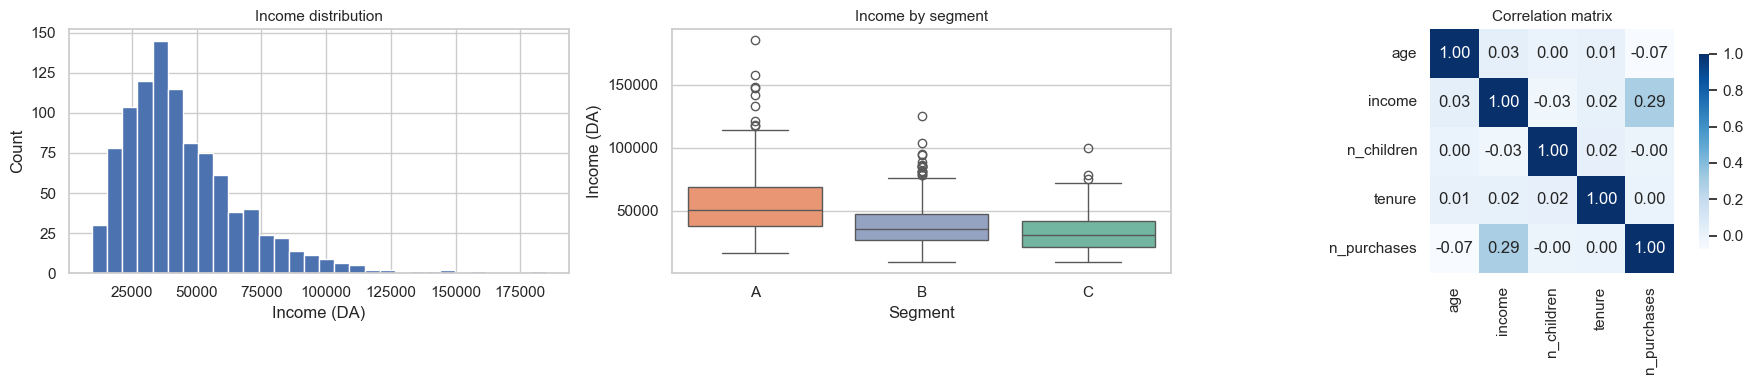

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# 1. Histogram: shape and outliers
axes[0].hist(df_clean["income"], bins=30, color="#4C72B0", edgecolor="white")
axes[0].set_title("Income distribution", fontsize=11)
axes[0].set_xlabel("Income (DA)")
axes[0].set_ylabel("Count")

# 2. Boxplot: comparison by segment
sns.boxplot(data=df_clean, x="segment", y="income", order=["A", "B", "C"],
            hue="segment", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Income by segment", fontsize=11)
axes[1].set_xlabel("Segment")
axes[1].set_ylabel("Income (DA)")

# 3. Correlation heatmap (numeric variables, without id)
sns.heatmap(df_clean[num_cols].corr(), annot=True, cmap="Blues", fmt=".2f",
            ax=axes[2], square=True, cbar_kws={"shrink": 0.8})
axes[2].set_title("Correlation matrix", fontsize=11)

plt.tight_layout()
plt.show()

**Expected findings**
1. **Histogram**: **right-skewed** distribution (skewness ≈ 1.4) — most clients between 20,000 and 60,000 DA, with a long tail up to ≈ 185,000 DA. These high incomes are plausible (they are no longer errors: the 999,999 code was handled).
2. **Boxplot**: segment **A** has the highest income (median ≈ 51,000 DA), ahead of **B** (≈ 36,000) and **C** (≈ 31,000). The B and C boxes overlap a lot; each segment has values beyond the whisker (skewness).
3. **Heatmap**: the only notable correlation is **income – n_purchases (r ≈ 0.29)**, weak to moderate. All others are close to 0. No pair with |r| > 0.8 → **no redundancy**, all variables are kept.

💡 *Reminder*: a correlation close to 0 does not rule out a **non-linear** relationship, and correlation ≠ causation.

---
## Step 4 — Document every decision
*Deliverable: completed notebook + conclusions. Traceability and reproducibility.*

**Decision log (expected)**

| # | Problem found | Decision | Justification | Rows before → after |
|---|---|---|---|---|
| 1 | 12 exact duplicates | `drop_duplicates(keep="first")` | a client counted twice skews all counts and means | 1,012 → 1,000 |
| 2 | Lowercase `a` / `b` segments (60 rows) | `replace({"a": "A", "b": "B"})` | otherwise 5 categories instead of 3 | 1,000 → 1,000 |
| 3 | `age` stored as text: 4 unreadable values | `to_numeric(errors="coerce")` | makes the column numeric, unreadable values become NaN | 1,000 → 1,000 |
| 4 | 8 out-of-range ages (−3, 150, 999…) + 4 NaN | `between(0, 120)` | unrealistic age → unreliable record, 1.2% of rows | 1,000 → 988 |
| 5 | Income = 999,999 (error code) | replaced with NaN | only the cell is wrong, the client is kept | 988 → 988 |
| 6 | 38 missing incomes (3.8%) | **k-NN (k = 5)** imputation, rounded to the hundred | keeps all rows, distorts the distribution the least | 988 → 988 |

**Conclusions (example)**
- The raw file had 4 kinds of defects (duplicates, categories, format, ranges). After cleaning: **988 clients, 8 variables, 0 missing values**.
- The three imputation methods give close means (< 0.5% difference) because the missing rate is low; the median squashes the spread, k-NN preserves it better.
- Income is right-skewed and clearly depends on the **segment** (A > B > C). No pair of variables is redundant (|r| < 0.8).
- **Limits**: k-NN only uses the non-standardised numeric variables; the segment, strongly linked to income, could be added (one-hot encoding, section 7) to improve the imputation.
- **Reproducibility**: re-running the notebook from top to bottom (*Kernel → Restart & Run All*) produces exactly the same `clients_clean.csv`.

---
## Summary

| Step | Command | What we learned |
|---|---|---|
| Duplicates | `duplicated()`, `drop_duplicates()` | count **before** removing |
| Categories | `replace()`, `value_counts()` | harmonise **before** analysing |
| Types | `pd.to_numeric(errors="coerce")` | unreadable becomes NaN, handled later |
| Ranges | `between()` | validate realistic values |
| Missing values | `dropna()`, `SimpleImputer`, `KNNImputer` | compare methods, not just means |
| Visualisation | `hist`, `sns.boxplot`, `sns.heatmap` | distribution, groups, correlations |

Order to respect: **Deduplicate → Harmonise → Type → Validate ranges → Impute → Visualise**.